# Building color analysis

This notebook computes the mean color of buildings in the Amsterdam street-view images, and shows how
building color varies over the city:

1. Buildings are cut out of each image using the SAM3 `building` segmentation. Images where buildings cover
   less than 5% of the image are skipped.
2. The image colors are converted from sRGB to linear RGB, so that averaging colors is physically meaningful
   (averaging is done on light intensity, not on gamma-encoded values).
3. The mean building color is computed per image.
4. The colors are aggregated on a grid and shown on a map.

The images and segmentations come from the `amsterdam-final` project (see `ams-map-workflow-confidence.ipynb`).

In [1]:
from streetscapes.utils.db_access import get_image, get_segmentations, iter_segmentations, open_project

PROJECT = "amsterdam-final"

db = open_project(PROJECT, read_only=True)
# Limit the memory DuckDB uses (it defaults to 80% of the system memory). Reading the polygons column
# requires ~2 GB, as DuckDB decompresses it in large blocks.
_ = db.raw_sql("SET memory_limit = '4GB'")

In [2]:
# enter the run ID of the SAM3 segmentation run you want to use:
RUN_ID = "sam3-2026-09-18T11:01:36.418"

BUILDING_LABEL = "building"

# Minimum fraction of the image that has to be covered by buildings.
MIN_BUILDING_FRACTION = 0.05

# Number of randomly sampled images to process. Set to None to process all images.
N_IMAGES = None
SEED = 42

# Grid cell size (m) for aggregating the colors on the map.
GRID_RESOLUTION = 100

# Number of images whose segmentations are loaded from the database in one query, and the number of
# threads that process the images of such a batch in parallel.
BATCH_SIZE = 100
N_WORKERS = 8

## Mean building color per image

All color computations are done in linear RGB. The linear colors are only converted back to sRGB for display.

`iter_segmentations` reads the segmentations from the database in batches (one query per batch instead of one
query per image), after which the images of a batch are processed by a pool of threads. Most of the per-image
work (decoding the image, rasterizing the masks, the color conversion) releases the GIL, so this scales
reasonably well.

In [3]:
import numpy as np
import rasterio.features

from streetscapes.utils.image_processing import linearize_image


def building_polygons(segmentation):
    """The polygons of the building instances of a segmentation."""
    return [inst.polygon for inst in segmentation.instances if inst.label == BUILDING_LABEL]


def linear_to_srgb(rgb_lin):
    """Inverse of the sRGB -> linear RGB conversion, for displaying linear colors."""
    rgb_lin = np.clip(rgb_lin, 0, 1)
    return np.where(rgb_lin <= 0.0031308, rgb_lin * 12.92, 1.055 * rgb_lin ** (1 / 2.4) - 0.055)


def building_color(uuid, polygons):
    """Mean linear RGB building color of an image, given its building polygons.

    Returns (color, image, mask). color is None if the image has too few building pixels.
    """
    image = get_image(uuid)
    shape = (image.height, image.width)
    if polygons:
        mask = rasterio.features.rasterize(polygons, out_shape=shape, dtype=np.uint8) > 0
    else:
        mask = np.zeros(shape, dtype=bool)
    if mask.mean() <= MIN_BUILDING_FRACTION:
        return None, image, mask
    return linearize_image(image)[mask].mean(axis=0), image, mask


def mean_building_color(uuid):
    """Same as building_color, but loads the segmentation of a single image."""
    segmentation = next(seg for seg in get_segmentations(uuid, project=PROJECT) if seg.id == RUN_ID)
    return building_color(uuid, building_polygons(segmentation))

A few examples of the cut out buildings and their mean color:

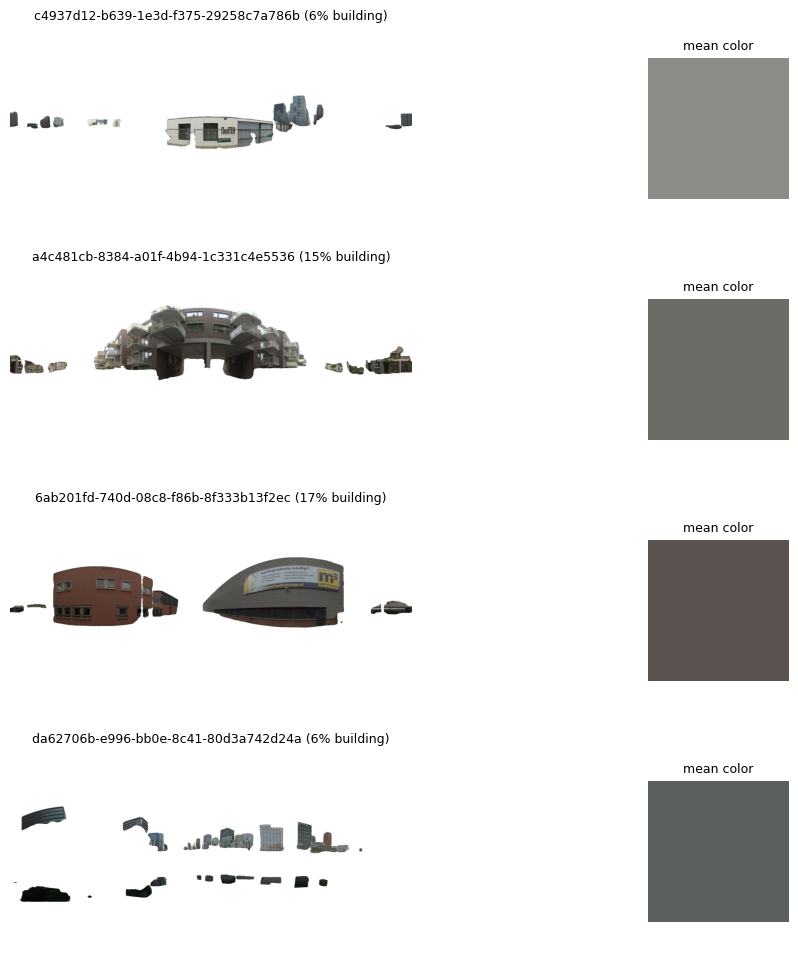

In [4]:
from matplotlib import pyplot as plt

images = db.table("images").uuid.to_pandas().astype(str)
rng = np.random.default_rng(SEED)
subset = images if N_IMAGES is None else images.iloc[rng.choice(len(images), N_IMAGES, replace=False)]

examples = []
for uuid in subset:
    color, image, mask = mean_building_color(uuid)
    if color is not None:
        examples.append((uuid, color, image, mask))
    if len(examples) == 4:
        break

fig, axes = plt.subplots(nrows=len(examples), ncols=2, figsize=(12, 3 * len(examples)), width_ratios=[5, 1])
for (uuid, color, image, mask), (ax_img, ax_color) in zip(examples, axes):
    cutout = np.asarray(image).copy()
    cutout[~mask] = 255
    ax_img.imshow(cutout)
    ax_img.set_title(f"{uuid} ({mask.mean():.0%} building)", fontsize=9)
    ax_color.imshow(linear_to_srgb(color)[None, None, :])
    ax_color.set_title("mean color", fontsize=9)
    for ax in (ax_img, ax_color):
        ax.axis("off")

Now compute the mean building color for all images in the subset:

In [5]:
import math
from concurrent.futures import ThreadPoolExecutor
from IPython.display import clear_output

import geopandas
from tqdm import tqdm

m = db.table("mapillary")
locations = (
    m.filter(m.image.isin(subset.tolist()))
    .select("image", "geometry")
    .to_pandas()
    .assign(image=lambda df: df["image"].astype(str))
    .drop_duplicates("image")
    .set_index("image")["geometry"]
)


def process_image(uuid, segmentation):
    """Returns a record for the image, or None if it has no location or too few building pixels."""
    if uuid not in locations.index:
        return None
    color, _, mask = building_color(uuid, building_polygons(segmentation))
    if color is None:
        return None
    return {
        "image": uuid,
        "r": color[0],
        "g": color[1],
        "b": color[2],
        "building_fraction": mask.mean(),
        "geometry": locations[uuid],
    }


records = []
batches = iter_segmentations(RUN_ID, subset.tolist(), batch_size=BATCH_SIZE, project=PROJECT, con=db)

with ThreadPoolExecutor(N_WORKERS) as pool:
    for batch in tqdm(batches, total=math.ceil(len(subset) / BATCH_SIZE)):
        results = pool.map(lambda item: process_image(*item), batch.items())
        records += [record for record in results if record is not None]
clear_output()  # clear progress bar for nicer saved notebook

colors = geopandas.GeoDataFrame(records, crs="EPSG:4326")
print(f"{len(colors)} of {len(subset)} images have more than {MIN_BUILDING_FRACTION:.0%} building pixels")
colors.head()

12147 of 19956 images have more than 5% building pixels


,image,r,g,b,building_fraction,geometry
0,c4937d12-b639-1e3d-f375-29258c7a786b,0.254408,0.263373,0.245918,0.056817,POINT (4.86712 52.33671)
1,a4c481cb-8384-a01f-4b94-1c331c4e5536,0.153669,0.149471,0.135330,0.146101,POINT (4.86715 52.37419)
2,6ab201fd-740d-08c8-f86b-8f333b13f2ec,0.103184,0.085137,0.076508,0.174136,POINT (4.86729 52.3821)
3,da62706b-e996-bb0e-8c41-80d3a742d24a,0.105704,0.116510,0.118119,0.059222,POINT (4.86772 52.33937)
4,bdb7ab3a-c8f7-ac26-45f8-b2ab2a5ab063,0.149376,0.130319,0.109879,0.122865,POINT (4.86771 52.35575)


## Colors on the map

Mean building color per image:

(np.float64(119143.53187690864),
 np.float64(127881.30995510571),
 np.float64(481156.76472904586),
 np.float64(489157.42802694294))

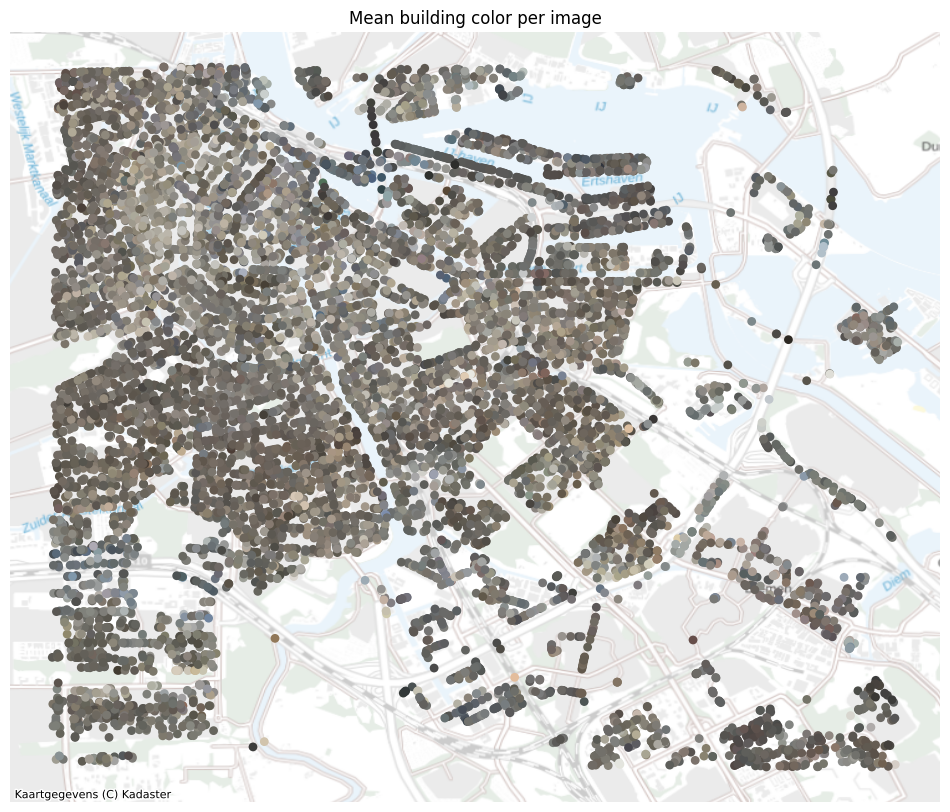

In [6]:
import contextily

colors_proj = colors.to_crs(28992)

fig, ax = plt.subplots(figsize=(12, 10))
ax.scatter(
    colors_proj.geometry.x,
    colors_proj.geometry.y,
    c=linear_to_srgb(colors_proj[["r", "g", "b"]].to_numpy()),
    s=40,
    edgecolors="none",
    zorder=2,
)
contextily.add_basemap(ax, crs=colors_proj.crs, source=contextily.providers.nlmaps.grijs)
ax.set_title("Mean building color per image")
ax.axis("off")

Aggregate the colors on a regular grid. The color of a grid cell is the mean (in linear RGB) of all images in that
cell.

Differences in overall brightness are largely caused by the lighting (sun or shade, overcast sky, camera
exposure). The right-hand map therefore shows the same colors scaled to equal brightness, which highlights
differences in hue (e.g. red/brown brick versus grey concrete).

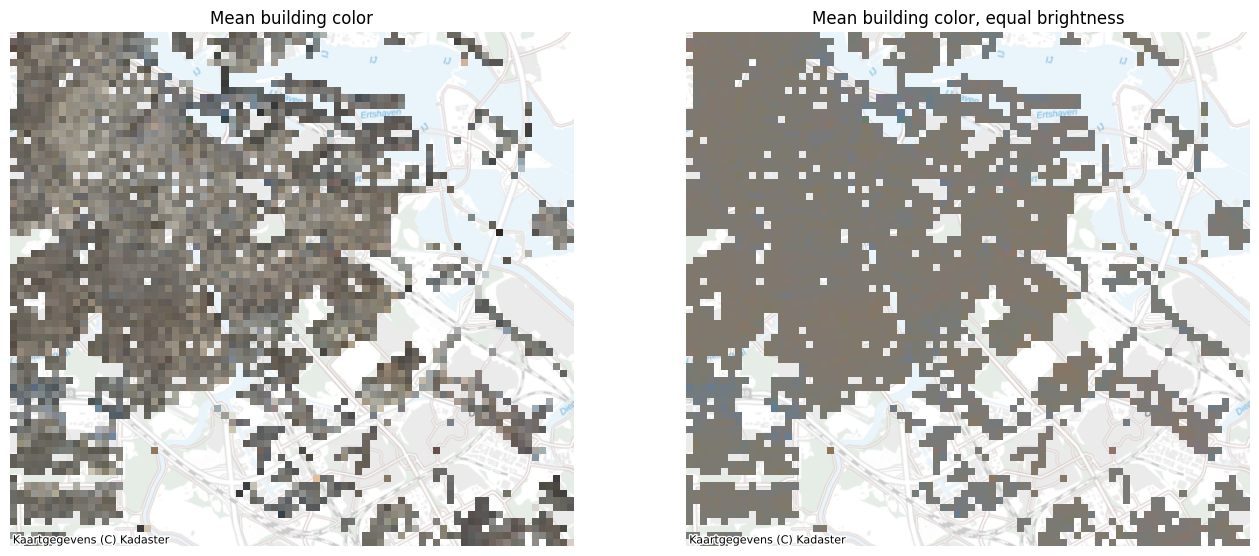

In [7]:
from streetscapes.utils.image_processing import luminance

bounds = colors_proj.total_bounds
cols = math.ceil((bounds[2] - bounds[0]) / GRID_RESOLUTION)
rows = math.ceil((bounds[3] - bounds[1]) / GRID_RESOLUTION)

cell_col = ((colors_proj.geometry.x - bounds[0]) // GRID_RESOLUTION).astype(int).clip(0, cols - 1)
cell_row = ((bounds[3] - colors_proj.geometry.y) // GRID_RESOLUTION).astype(int).clip(0, rows - 1)
cell_means = colors_proj.assign(row=cell_row, col=cell_col).groupby(["row", "col"])[["r", "g", "b"]].mean()

grid = np.full((rows, cols, 3), np.nan)
grid[cell_means.index.get_level_values("row"), cell_means.index.get_level_values("col")] = cell_means.to_numpy()

# Same colors, scaled so that every cell has the mean luminance of all cells
grid_luminance = luminance(grid)
grid_normalized = grid * (np.nanmean(grid_luminance) / grid_luminance)[..., None]


def to_rgba(grid_lin):
    rgba = np.zeros((*grid_lin.shape[:2], 4))
    valid = ~np.isnan(grid_lin).any(axis=-1)
    rgba[valid, :3] = linear_to_srgb(grid_lin[valid])
    rgba[valid, 3] = 1
    return rgba


extent = (bounds[0], bounds[0] + cols * GRID_RESOLUTION, bounds[3] - rows * GRID_RESOLUTION, bounds[3])
fig, axes = plt.subplots(ncols=2, figsize=(16, 8), sharex=True, sharey=True)
for ax, (title, g) in zip(axes, [("Mean building color", grid), ("Mean building color, equal brightness", grid_normalized)]):
    ax.imshow(to_rgba(g), extent=extent, interpolation="nearest", zorder=2)
    contextily.add_basemap(ax, crs=colors_proj.crs, source=contextily.providers.nlmaps.grijs)
    ax.set_title(title)
    ax.axis("off")

## Mean building hue

The hue of the mean building color (HSV hue of the sRGB color, in degrees), per grid cell and as a histogram over
all images. Taking the hue of the mean color avoids having to average hue angles, which are circular.

Text(0.5, 1.0, 'Hue of the mean building color per image')

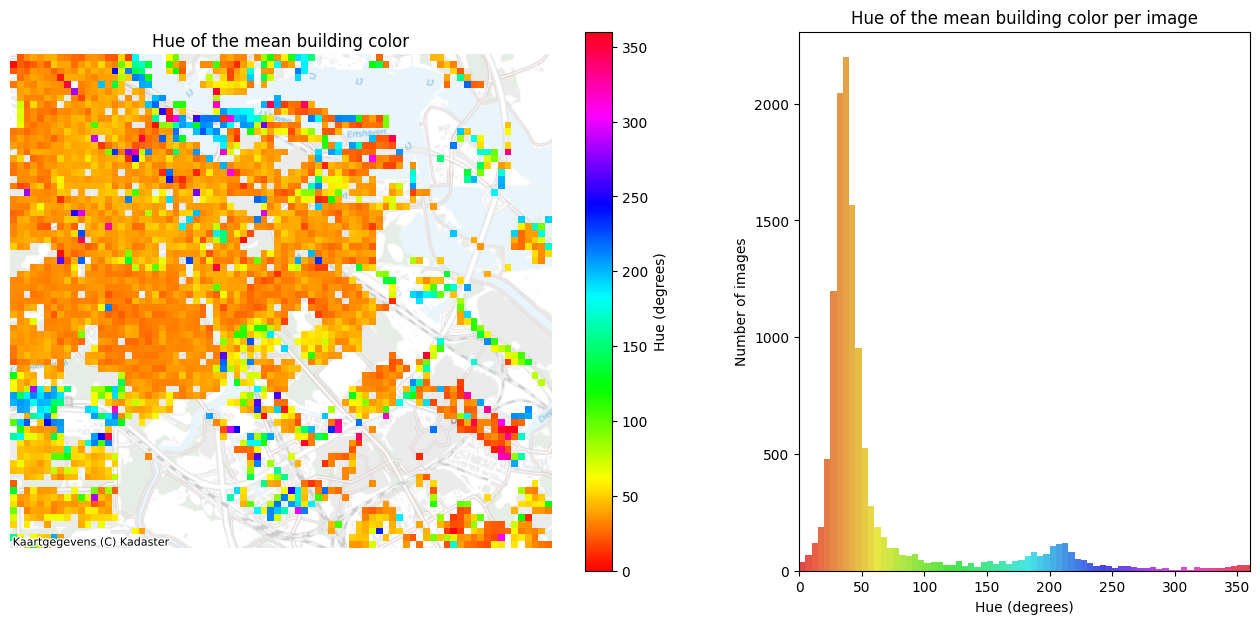

In [8]:
from matplotlib.colors import hsv_to_rgb, rgb_to_hsv


def hue_degrees(rgb_lin):
    return rgb_to_hsv(linear_to_srgb(rgb_lin))[..., 0] * 360


valid = ~np.isnan(grid).any(axis=-1)
grid_hue = np.full(grid.shape[:2], np.nan)
grid_hue[valid] = hue_degrees(grid[valid])
image_hue = hue_degrees(colors_proj[["r", "g", "b"]].to_numpy())

fig, (ax_map, ax_hist) = plt.subplots(ncols=2, figsize=(16, 7), width_ratios=[3, 2])

hue_image = ax_map.imshow(grid_hue, extent=extent, cmap="hsv", vmin=0, vmax=360, interpolation="nearest", zorder=2)
contextily.add_basemap(ax_map, crs=colors_proj.crs, source=contextily.providers.nlmaps.grijs)
fig.colorbar(hue_image, ax=ax_map, label="Hue (degrees)")
ax_map.set_title("Hue of the mean building color")
ax_map.axis("off")

counts, edges, patches = ax_hist.hist(image_hue, bins=np.arange(0, 365, 5))
for patch, left in zip(patches, edges[:-1]):
    patch.set_facecolor(hsv_to_rgb((left / 360, 0.7, 0.9)))
ax_hist.set_xlim(0, 360)
ax_hist.set_xlabel("Hue (degrees)")
ax_hist.set_ylabel("Number of images")
ax_hist.set_title("Hue of the mean building color per image")